In [1]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights
from torchvision import datasets
from torch.utils.data import DataLoader, random_split
import copy
from mininn.training import train_one_epoch, evaluate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights = ResNet18_Weights.DEFAULT

In [2]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import torch

# Assumes the notebook kernel is running from DeepVisionLab/.
PROJECT_DIR = Path.cwd()
FIGURES_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"

FIGURES_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

def save_figure(fig, name):
    """PNG for sharing; vector PDF for reports."""
    fig.savefig(
        FIGURES_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )
    fig.savefig(
        FIGURES_DIR / f"{name}.pdf",
        bbox_inches="tight",
        facecolor="white",
    )

def save_results(name, data):
    with open(RESULTS_DIR / f"{name}.json", "w") as f:
        json.dump(data, f, indent=2)

print("Figures:", FIGURES_DIR)
print("Results:", RESULTS_DIR)

Figures: /home/devansh/main/machine_learning/deep-learning-lab/DeepVisionLab/figures
Results: /home/devansh/main/machine_learning/deep-learning-lab/DeepVisionLab/results


In [3]:
class FrozenResNet18(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.backbone = resnet18(weights=weights)
        feature_count = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()

        for p in self.backbone.parameters():
            p.requires_grad_(False)

        self.classifier = nn.Linear(feature_count, num_classes)
        self.backbone.eval()

    def train(self, mode=True):
        super().train(mode)

        # Keep BatchNorm statistics fixed, even during training.
        self.backbone.eval()
        return self

    def forward(self, x):
        with torch.no_grad():
            features = self.backbone(x)

        return self.classifier(features)


torch.manual_seed(42)
transfer_model = FrozenResNet18().to(device)

print("Classifier:", transfer_model.classifier)

transfer_model.train()
print("Backbone training:", transfer_model.backbone.training)
print("Classifier training:", transfer_model.classifier.training)

Classifier: Linear(in_features=512, out_features=10, bias=True)
Backbone training: False
Classifier training: True


In [4]:
preprocess = weights.transforms()

transfer_dataset = datasets.CIFAR10(
    root="../data_1",
    train=True,
    download=True,
    transform=preprocess,
)

transfer_train_subset, transfer_val_subset = random_split(
    transfer_dataset,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42),
)

transfer_train_loader = DataLoader(
    transfer_train_subset,
    batch_size=64,
    shuffle=True,
)

transfer_train_eval_loader = DataLoader(
    transfer_train_subset,
    batch_size=64,
    shuffle=False,
)

transfer_val_loader = DataLoader(
    transfer_val_subset,
    batch_size=64,
    shuffle=False,
)

images, labels = next(iter(transfer_train_loader))
print("Images:", images.shape)
print("Labels:", labels.shape)

Images: torch.Size([64, 3, 224, 224])
Labels: torch.Size([64])


In [5]:
transfer_optimizer = torch.optim.AdamW(
    transfer_model.classifier.parameters(),
    lr=0.001,
    weight_decay=0.01,
)

best_accuracy = -1.0
best_epoch = 0
best_state = None

for epoch in range(1, 6):
    train_loss = train_one_epoch(
        transfer_model,
        transfer_train_loader,
        transfer_optimizer,
        device,
    )

    val_metrics = evaluate(
        transfer_model, transfer_val_loader, device
    )

    if val_metrics["accuracy"] > best_accuracy:
        best_accuracy = val_metrics["accuracy"]
        best_epoch = epoch
        best_state = copy.deepcopy(transfer_model.state_dict())

    print(
        f"Epoch {epoch} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.2f}%"
    )

transfer_model.load_state_dict(best_state)

train_metrics = evaluate(
    transfer_model, transfer_train_eval_loader, device
)
val_metrics = evaluate(
    transfer_model, transfer_val_loader, device
)

print(f"\nRestored epoch: {best_epoch}")
print(f"Training accuracy: {train_metrics['accuracy']:.2f}%")
print(f"Validation accuracy: {val_metrics['accuracy']:.2f}%")

torch.save(
    {
        "model_state": transfer_model.state_dict(),
        "epoch": best_epoch,
        "val_accuracy": val_metrics["accuracy"],
        "pretrained_weights": "ResNet18_Weights.IMAGENET1K_V1",
    },
    "best_frozen_resnet18.pt",
)

Epoch 1 | Train loss: 0.6338 | Val loss: 0.4484 | Val accuracy: 84.58%
Epoch 2 | Train loss: 0.4286 | Val loss: 0.4081 | Val accuracy: 86.08%
Epoch 3 | Train loss: 0.3980 | Val loss: 0.3915 | Val accuracy: 86.58%
Epoch 4 | Train loss: 0.3837 | Val loss: 0.3908 | Val accuracy: 86.12%
Epoch 5 | Train loss: 0.3741 | Val loss: 0.3943 | Val accuracy: 85.92%

Restored epoch: 3
Training accuracy: 87.32%
Validation accuracy: 86.58%


In [6]:
class FineTuneResNet18(FrozenResNet18):
    def __init__(self, num_classes=10):
        super().__init__(num_classes)

        # Unfreeze only the final residual stage.
        for p in self.backbone.layer4.parameters():
            p.requires_grad_(True)

    def forward(self, x):
        # Gradient tracking is now enabled.
        features = self.backbone(x)
        return self.classifier(features)


finetune_model = FineTuneResNet18().to(device)
finetune_model.load_state_dict(transfer_model.state_dict())

finetune_optimizer = torch.optim.AdamW(
    [
        {
            "params": finetune_model.backbone.layer4.parameters(),
            "lr": 1e-5,
        },
        {
            "params": finetune_model.classifier.parameters(),
            "lr": 1e-4,
        },
    ],
    weight_decay=0.01,
)

In [7]:
baseline = evaluate(
    finetune_model, transfer_val_loader, device
)

best_accuracy = baseline["accuracy"]
best_epoch = 0  # Before fine-tuning
best_state = copy.deepcopy(finetune_model.state_dict())

for epoch in range(1, 6):
    train_loss = train_one_epoch(
        finetune_model,
        transfer_train_loader,
        finetune_optimizer,
        device,
    )

    val_metrics = evaluate(
        finetune_model, transfer_val_loader, device
    )

    if val_metrics["accuracy"] > best_accuracy:
        best_accuracy = val_metrics["accuracy"]
        best_epoch = epoch
        best_state = copy.deepcopy(finetune_model.state_dict())

    print(
        f"Epoch {epoch} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.2f}%"
    )

finetune_model.load_state_dict(best_state)

train_metrics = evaluate(
    finetune_model, transfer_train_eval_loader, device
)
val_metrics = evaluate(
    finetune_model, transfer_val_loader, device
)

print(f"\nRestored fine-tuning epoch: {best_epoch}")
print(f"Training accuracy: {train_metrics['accuracy']:.2f}%")
print(f"Validation accuracy: {val_metrics['accuracy']:.2f}%")

torch.save(
    {
        "model_state": finetune_model.state_dict(),
        "finetune_epoch": best_epoch,
        "val_accuracy": val_metrics["accuracy"],
        "pretrained_weights": "ResNet18_Weights.IMAGENET1K_V1",
    },
    "best_finetuned_resnet18.pt",
)

Epoch 1 | Train loss: 0.3273 | Val loss: 0.3051 | Val accuracy: 89.10%
Epoch 2 | Train loss: 0.2293 | Val loss: 0.2978 | Val accuracy: 89.66%
Epoch 3 | Train loss: 0.1712 | Val loss: 0.2697 | Val accuracy: 90.46%
Epoch 4 | Train loss: 0.1259 | Val loss: 0.2576 | Val accuracy: 91.36%
Epoch 5 | Train loss: 0.0909 | Val loss: 0.2646 | Val accuracy: 91.10%

Restored fine-tuning epoch: 4
Training accuracy: 97.79%
Validation accuracy: 91.36%


In [8]:
transfer_test_dataset = datasets.CIFAR10(
    root="../data_1",
    train=False,
    download=True,
    transform=preprocess,
)

transfer_test_loader = DataLoader(
    transfer_test_dataset,
    batch_size=64,
    shuffle=False,
)

test_metrics = evaluate(
    finetune_model,
    transfer_test_loader,
    device,
)

print(f"Test images: {len(transfer_test_dataset)}")
print(f"Test loss: {test_metrics['loss']:.4f}")
print(f"Test accuracy: {test_metrics['accuracy']:.2f}%")

Test images: 10000
Test loss: 0.2755
Test accuracy: 91.05%


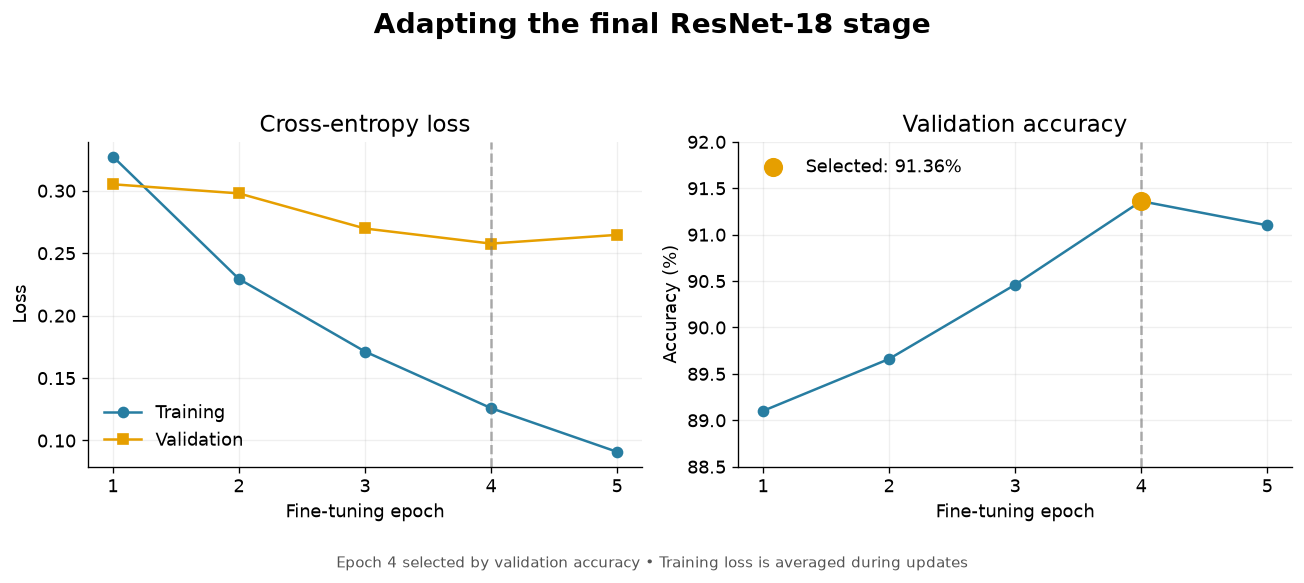

In [9]:
finetune_history = {
    "epoch": [1, 2, 3, 4, 5],
    "train_loss": [0.3273, 0.2293, 0.1712, 0.1259, 0.0909],
    "val_loss": [0.3051, 0.2978, 0.2697, 0.2576, 0.2646],
    "val_accuracy": [89.10, 89.66, 90.46, 91.36, 91.10],
    "selected_epoch": 4,
    "source": "Recorded notebook output, rounded to displayed precision",
}

save_results("resnet18_finetuning_history", finetune_history)

epochs = finetune_history["epoch"]
selected_epoch = finetune_history["selected_epoch"]
selected_index = epochs.index(selected_epoch)

fig, axes = plt.subplots(figsize=(11, 4.8), ncols=2)

axes[0].plot(
    epochs,
    finetune_history["train_loss"],
    marker="o",
    color="#277DA1",
    label="Training",
)
axes[0].plot(
    epochs,
    finetune_history["val_loss"],
    marker="s",
    color="#E69F00",
    label="Validation",
)
axes[0].set_title("Cross-entropy loss")
axes[0].set_ylabel("Loss")
axes[0].legend(frameon=False)

axes[1].plot(
    epochs,
    finetune_history["val_accuracy"],
    marker="o",
    color="#277DA1",
)
axes[1].scatter(
    [selected_epoch],
    [finetune_history["val_accuracy"][selected_index]],
    color="#E69F00",
    s=110,
    zorder=3,
    label="Selected: 91.36%",
)
axes[1].set_title("Validation accuracy")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(88.5, 92)
axes[1].legend(frameon=False)

for ax in axes:
    ax.axvline(
        selected_epoch,
        color="#777777",
        linestyle="--",
        alpha=0.6,
    )
    ax.set_xlabel("Fine-tuning epoch")
    ax.set_xticks(epochs)
    ax.grid(alpha=0.2)

fig.suptitle(
    "Adapting the final ResNet-18 stage",
    fontsize=17,
    fontweight="bold",
)
fig.text(
    0.5, 0.015,
    "Epoch 4 selected by validation accuracy • "
    "Training loss is averaged during updates",
    ha="center",
    fontsize=9,
    color="#555555",
)

fig.tight_layout(rect=[0, 0.06, 1, 0.92])
save_figure(fig, "resnet18_finetuning_curves")
plt.show()

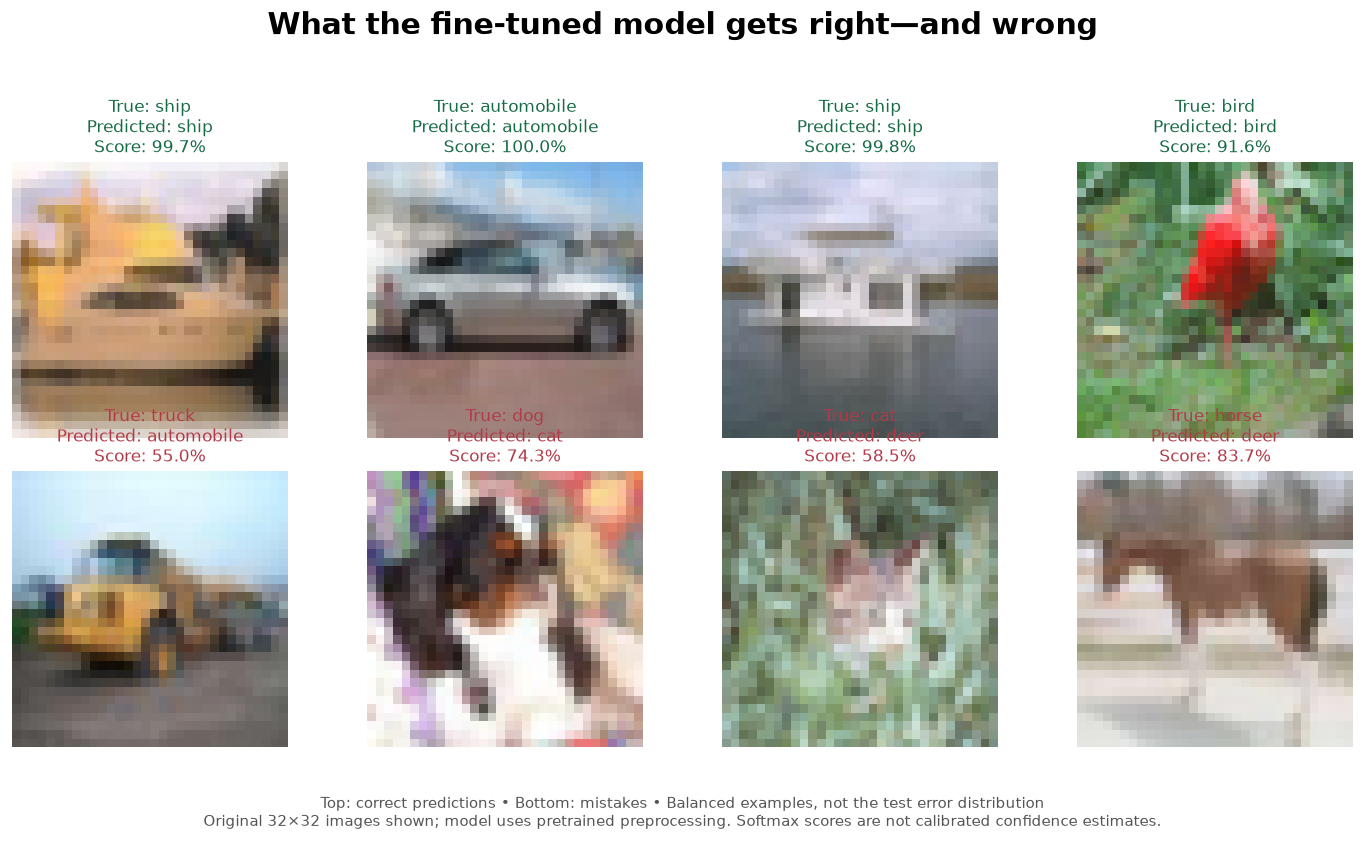

In [10]:
from torchvision import datasets

# Raw images for display; preprocessing is applied separately for inference.
display_test_dataset = datasets.CIFAR10(
    root=transfer_test_dataset.root,
    train=False,
    download=False,
    transform=None,
)

class_names = display_test_dataset.classes

# Fixed random order avoids manually choosing attractive examples.
sample_generator = torch.Generator().manual_seed(42)
sample_order = torch.randperm(
    len(display_test_dataset),
    generator=sample_generator,
).tolist()

correct_examples = []
incorrect_examples = []

finetune_model.eval()

with torch.no_grad():
    for start in range(0, len(sample_order), 64):
        indices = sample_order[start:start + 64]
        samples = [display_test_dataset[i] for i in indices]

        inputs = torch.stack([
            preprocess(image) for image, _ in samples
        ]).to(device)

        probabilities = finetune_model(inputs).softmax(dim=1)
        scores, predictions = probabilities.max(dim=1)

        predictions = predictions.cpu().tolist()
        scores = scores.cpu().tolist()

        for index, (_, label), prediction, score in zip(
            indices, samples, predictions, scores
        ):
            record = {
                "dataset_index": index,
                "true_class": class_names[label],
                "predicted_class": class_names[prediction],
                "softmax_score": score,
            }

            destination = (
                correct_examples
                if prediction == label
                else incorrect_examples
            )

            if len(destination) < 4:
                destination.append(record)

        if len(correct_examples) == 4 and len(incorrect_examples) == 4:
            break

selected_examples = correct_examples + incorrect_examples

save_results("resnet18_prediction_examples", {
    "sampling_seed": 42,
    "selection": "First four correct and four incorrect in shuffled order",
    "examples": selected_examples,
})

fig, axes = plt.subplots(2, 4, figsize=(12, 7))

for ax, record in zip(axes.flat, selected_examples):
    image, _ = display_test_dataset[record["dataset_index"]]
    correct = record["true_class"] == record["predicted_class"]

    ax.imshow(image, interpolation="nearest")
    ax.set_title(
        f"True: {record['true_class']}\n"
        f"Predicted: {record['predicted_class']}\n"
        f"Score: {record['softmax_score']:.1%}",
        fontsize=10,
        color="#176B45" if correct else "#B23A48",
    )
    ax.axis("off")

fig.suptitle(
    "What the fine-tuned model gets right—and wrong",
    fontsize=18,
    fontweight="bold",
    y=0.99,
)
fig.text(
    0.5, 0.02,
    "Top: correct predictions • Bottom: mistakes • "
    "Balanced examples, not the test error distribution\n"
    "Original 32×32 images shown; model uses pretrained preprocessing. "
    "Softmax scores are not calibrated confidence estimates.",
    ha="center",
    fontsize=9,
    color="#555555",
)

fig.tight_layout(rect=[0, 0.09, 1, 0.94])
save_figure(fig, "resnet18_prediction_examples")
plt.show()